# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [137]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [138]:
df=pd.read_csv("cleaned_aviation_data.csv")

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

1. Create Aircraft size groups

In [139]:
df['Aircraft_Size'] = np.where (
    df['Total.Passengers'] <=20,
    'Small_Aircraft',
    'Large_Aircraft'
)


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

1. Keep only makes with atleast 1 accident record

In [140]:
make_counts = df.groupby('Make').size()

valid_makes = make_counts[make_counts > 0].index

df_makes = df[df['Make'].isin(valid_makes)]

2. Calculate mean serious/fatal injury fraction

In [141]:
make_injury = (
    df_makes
    .groupby(['Aircraft_Size','Make'])['fatal.seriuos.rate']
    .mean()
    .reset_index()
)


3. Select lowest-risk makes.

In [142]:
small_best = (
    make_injury[make_injury['Aircraft_Size']=='Small_Aircraft']
    .sort_values('fatal.seriuos.rate')
    .head(15)
)

large_best = (
    make_injury[make_injury['Aircraft_Size']=='Large_Aircraft']
    .sort_values('fatal.seriuos.rate')
    .head(15)
)


4. Side-by-Side Plot of Lowest Injury Rates

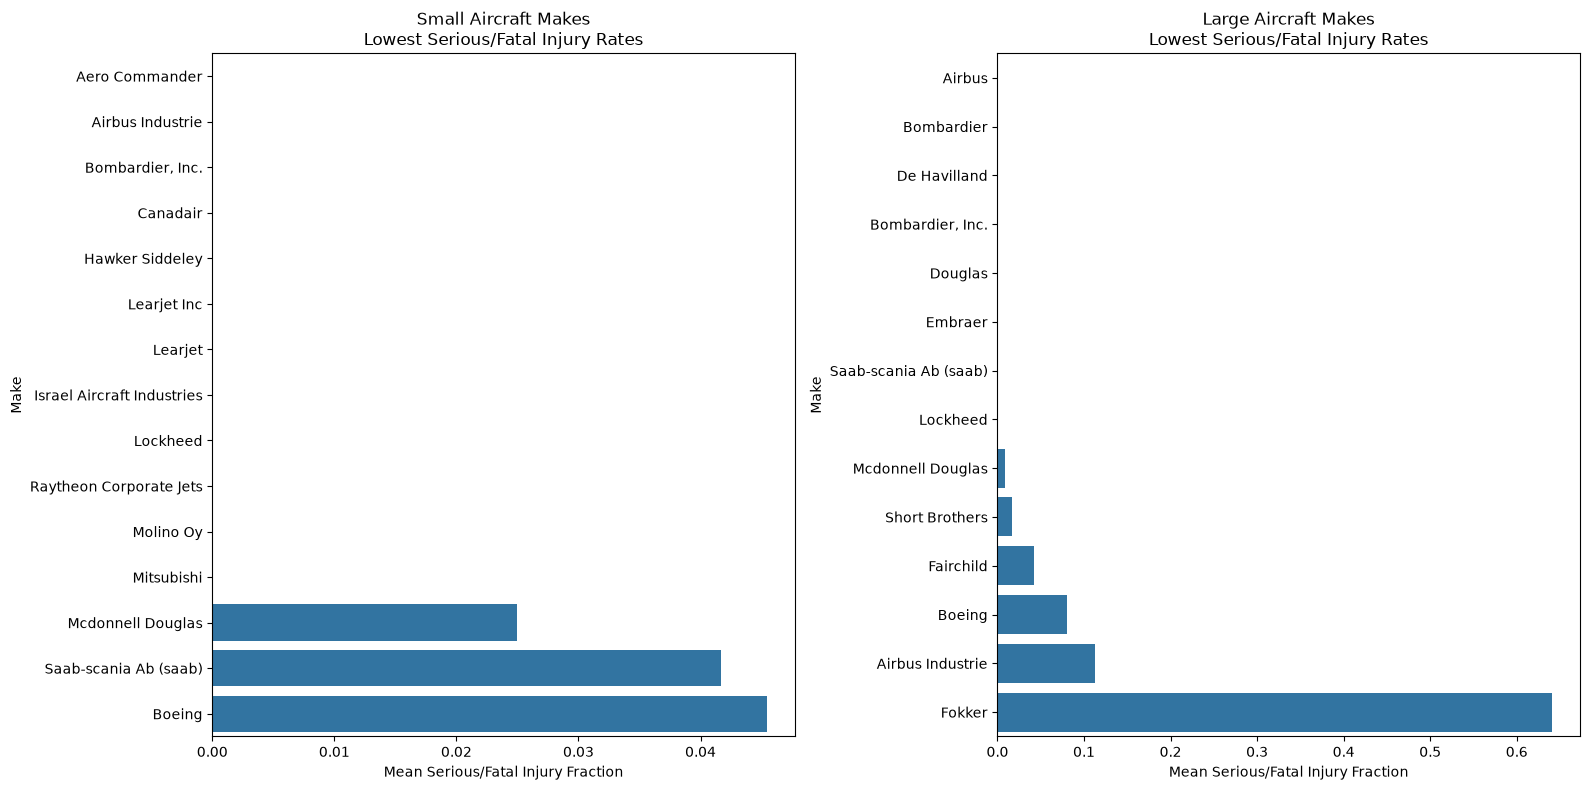

In [143]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2, figsize=(16,8))

sns.barplot(
    data=small_best,
    y='Make',
    x='fatal.seriuos.rate',
    ax=axes[0]
)

axes[0].set_title('Small Aircraft Makes\nLowest Serious/Fatal Injury Rates')
axes[0].set_xlabel('Mean Serious/Fatal Injury Fraction')

sns.barplot(
    data=large_best,
    y='Make',
    x='fatal.seriuos.rate',
    ax=axes[1]
)

axes[1].set_title('Large Aircraft Makes\nLowest Serious/Fatal Injury Rates')
axes[1].set_xlabel('Mean Serious/Fatal Injury Fraction')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

I displayed the 20 lowest mean seiuos/fatal injury rates because 10 lowest had zero mean

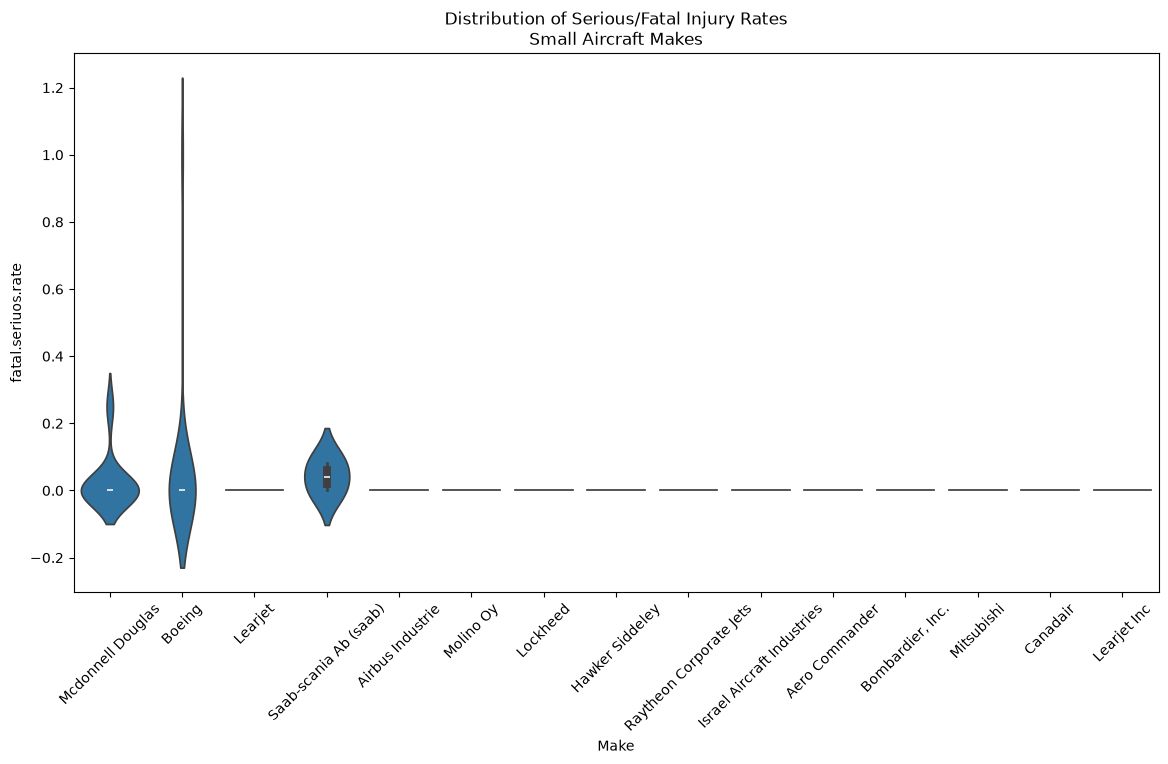

In [144]:
top10_small = small_best.head(20)['Make']

small_violin = df_makes[
    (df_makes['Aircraft_Size']=='Small_Aircraft') &
    (df_makes['Make'].isin(top10_small))
]

plt.figure(figsize=(14,7))

sns.violinplot(
    data=small_violin,
    x='Make',
    y='fatal.seriuos.rate'
)

plt.xticks(rotation=45)
plt.title('Distribution of Serious/Fatal Injury Rates\nSmall Aircraft Makes')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

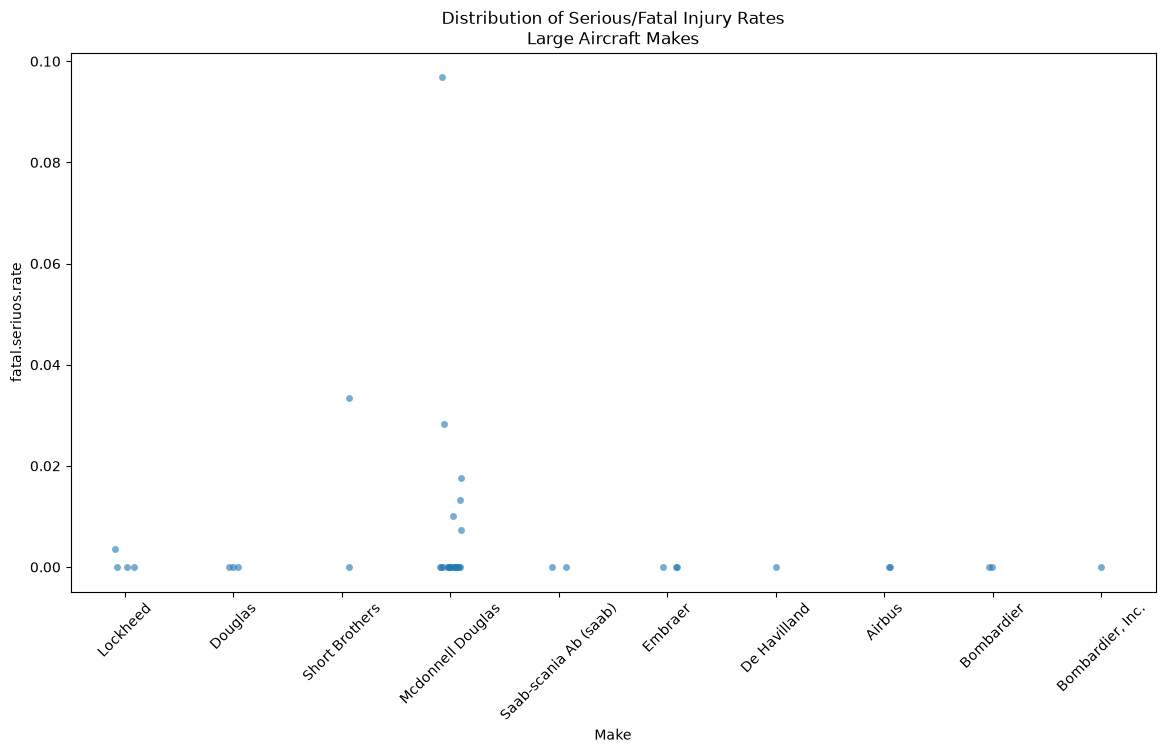

In [145]:
top10_large = large_best.head(10)['Make']

large_strip = df_makes[
    (df_makes['Aircraft_Size']=='Large_Aircraft') &
    (df_makes['Make'].isin(top10_large))
]

plt.figure(figsize=(14,7))

sns.stripplot(
    data=large_strip,
    x='Make',
    y='fatal.seriuos.rate',
    jitter=True,
    alpha=.6
)

plt.xticks(rotation=45)
plt.title('Distribution of Serious/Fatal Injury Rates\nLarge Aircraft Makes')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

Calculate the mean damage score by Make

In [146]:
damage_make = (
    df_makes
    .groupby(['Aircraft_Size', 'Make'])['damage.score']
    .mean()
    .reset_index()
)

Lowest Damage Severity Makes

Small Aircraft

In [147]:
small_damage = (
    damage_make[damage_make['Aircraft_Size'] == 'Small_Aircraft']
    .sort_values('damage.score')
    .head(15)
)

Large Aircraft

In [148]:
large_damage = (
    damage_make[damage_make['Aircraft_Size'] == 'Large_Aircraft']
    .sort_values('damage.score')
    .head(15)
)

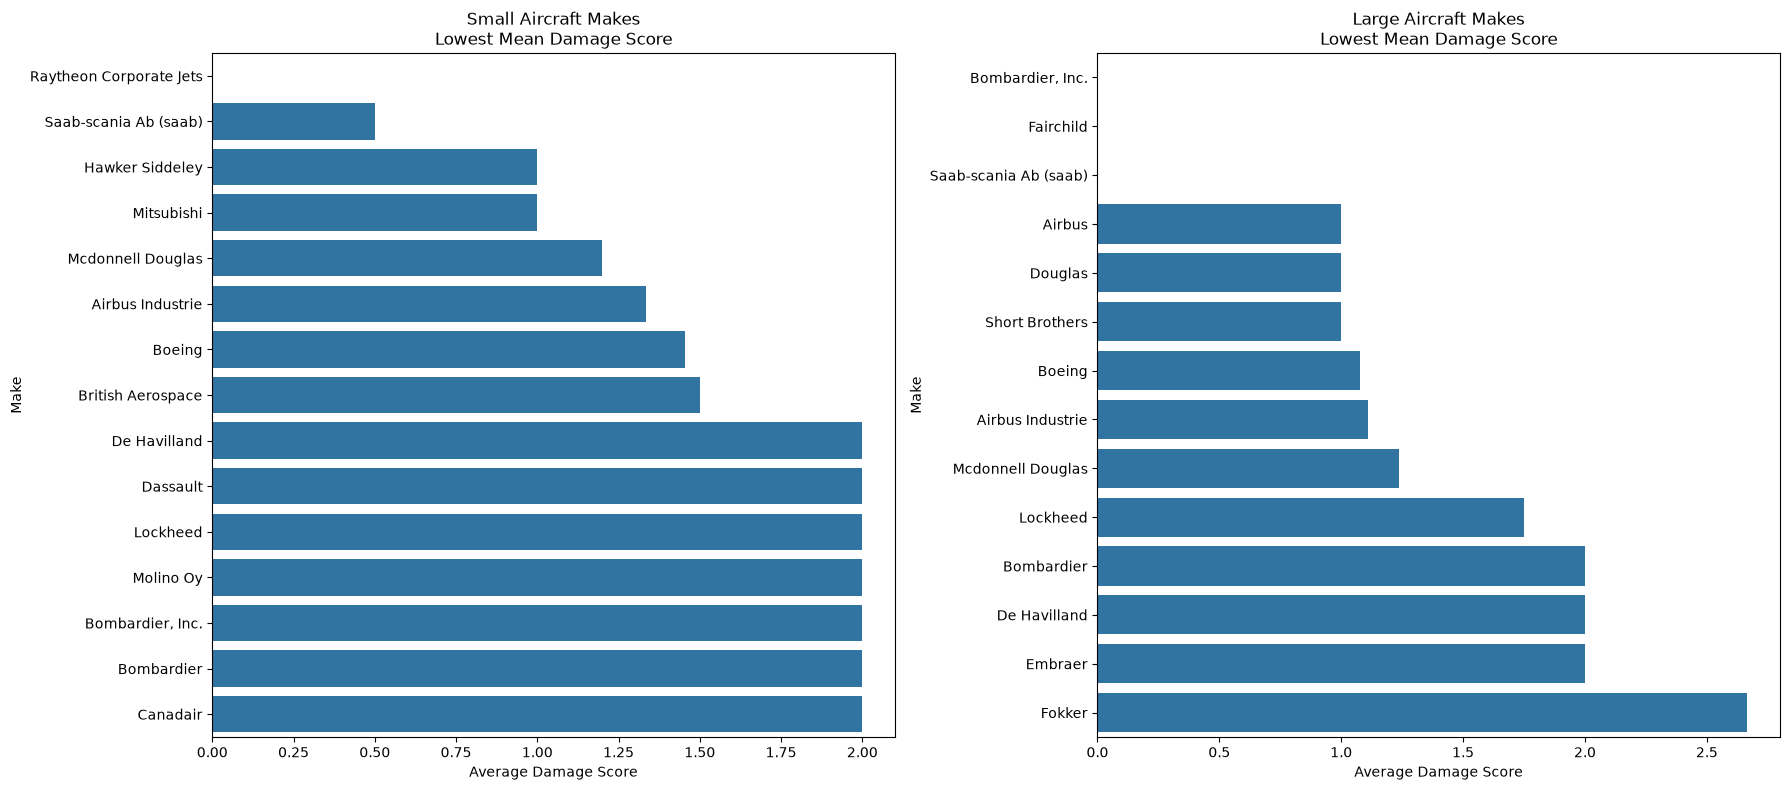

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(18,8))

sns.barplot(
data=small_damage,
y='Make',
x='damage.score',
ax=axes[0],

)

axes[0].set_title('Small Aircraft Makes\nLowest Mean Damage Score')
axes[0].set_xlabel('Average Damage Score')

sns.barplot(
data=large_damage,
y='Make',
x='damage.score',
ax=axes[1],

)

axes[1].set_title('Large Aircraft Makes\nLowest Mean Damage Score')
axes[1].set_xlabel('Average Damage Score')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

1. Combine Injury Risk and Damage Severity

In [150]:
safety_summary = (
    df_makes
    .groupby(['Aircraft_Size','Make'])
    .agg({
        'fatal.seriuos.rate':'mean',
        'damage.score':'mean'
    })
    .reset_index()
)

2. Best Small Aircraft Makes

In [151]:
best_small = (
safety_summary[safety_summary['Aircraft_Size']=='Small_Aircraft']
.sort_values(
['fatal.seriuos.rate','damage.score']
)
.head(15)
)

best_small

,Aircraft_Size,Make,fatal.seriuos.rate,damage.score
38,Small_Aircraft,Raytheon Corporate Jets,0.000000,0.000000
29,Small_Aircraft,Hawker Siddeley,0.000000,1.000000
35,Small_Aircraft,Mitsubishi,0.000000,1.000000
15,Small_Aircraft,Airbus Industrie,0.000000,1.333333
14,Small_Aircraft,Aero Commander,0.000000,2.000000
19,Small_Aircraft,"Bombardier, Inc.",0.000000,2.000000
22,Small_Aircraft,Canadair,0.000000,2.000000
30,Small_Aircraft,Israel Aircraft Industries,0.000000,2.000000
32,Small_Aircraft,Learjet Inc,0.000000,2.000000
33,Small_Aircraft,Lockheed,0.000000,2.000000


3. Best Large Aircraft Makes

In [152]:
best_large = (
    safety_summary[safety_summary['Aircraft_Size']=='Large_Aircraft']
    .sort_values(
        ['fatal.seriuos.rate','damage.score']
    )
    .head(15)
)

best_large

,Aircraft_Size,Make,fatal.seriuos.rate,damage.score
4,Large_Aircraft,"Bombardier, Inc.",0.000000,0.000000
12,Large_Aircraft,Saab-scania Ab (saab),0.000000,0.000000
0,Large_Aircraft,Airbus,0.000000,1.000000
6,Large_Aircraft,Douglas,0.000000,1.000000
3,Large_Aircraft,Bombardier,0.000000,2.000000
5,Large_Aircraft,De Havilland,0.000000,2.000000
7,Large_Aircraft,Embraer,0.000000,2.000000
10,Large_Aircraft,Lockheed,0.000883,1.750000
11,Large_Aircraft,Mcdonnell Douglas,0.008258,1.238095
13,Large_Aircraft,Short Brothers,0.016667,1.000000


In the above recomendation for best small and large aircrafts, I have combined injury risk and damage severity due to the following reasons":
1. An airplane might have low passenger injury rates but frequently suffer substantial aircraft damage.
2. an airplanve may have low damage severity but relatively high injury rates.

Sorting on both metrics identifies aircraft makes that are safer for passengers and more likely to avoid severe aircraft destruction in case of an incident.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

1. Filter to Plane Types with at Least 10 Records

In [176]:
type_counts = (
    df
    .groupby(['Aircraft_Size', 'Plane_Type'])
    .size()
    .reset_index(name='count')
)

valid_types = type_counts[type_counts['count'] >= 10]

plane_df = df.merge(
    valid_types[['Aircraft_Size','Plane_Type']],
    on=['Aircraft_Size','Plane_Type'],
    how='inner'
)


2. Mean Fatal/Serious Injury Fraction by Plane Type

In [160]:
type_summary = (
    plane_df
    .groupby(['Aircraft_Size', 'Plane_Type'])
    ['fatal.seriuos.rate']
    .mean()
    .reset_index()
)

**Larger planes**

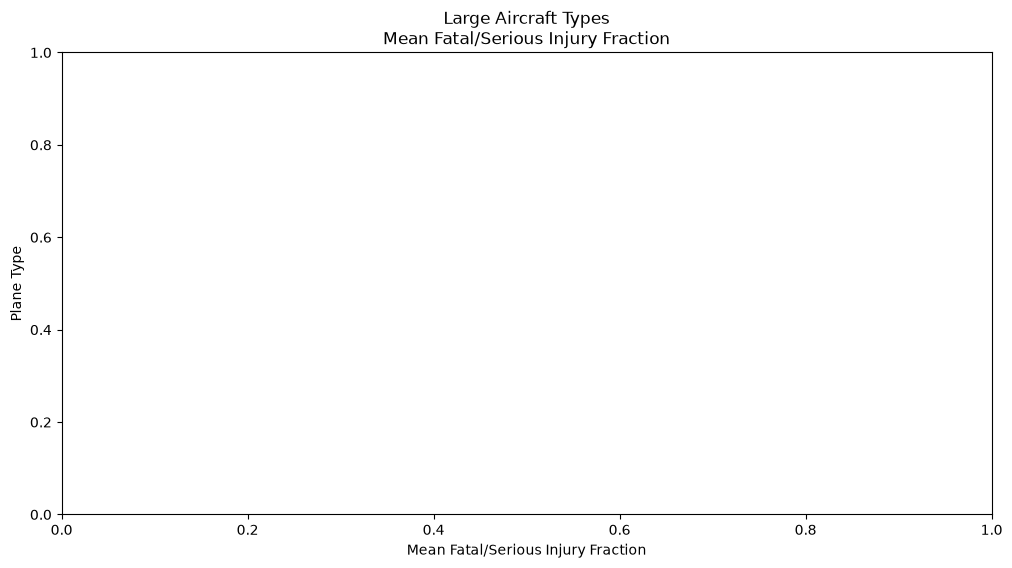

In [161]:
large_types = (
    type_summary[type_summary['Aircraft_Size'] == 'Large_Aircraft']
    .sort_values('fatal.seriuos.rate')
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=large_types,
    x='fatal.seriuos.rate',
    y='Plane_Type'
    
)

plt.title('Large Aircraft Types\nMean Fatal/Serious Injury Fraction')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Plane Type')

plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [166]:
small_types = (
    type_summary[type_summary['Aircraft_Size'] == 'Small_Aircraft']
    .sort_values('fatal.seriuos.rate')
    .head(10)
)
small_types

,Aircraft_Size,Plane_Type,fatal.seriuos.rate
0,Small_Aircraft,CESSNA_208B,0.604167


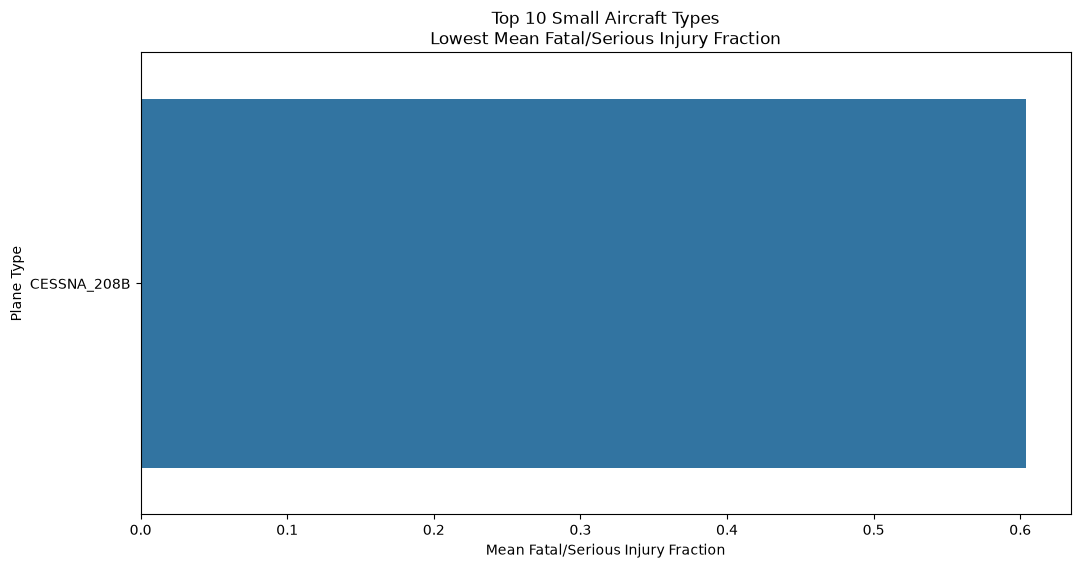

In [165]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=small_types,
    x='fatal.seriuos.rate',
    y='Plane_Type',
)

plt.title('Top 10 Small Aircraft Types\nLowest Mean Fatal/Serious Injury Fraction')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Plane Type')

plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Large aircraft types generally tend to exhibit lower fatal/serious injury fractions because they are designed with stronger structural integrity, enhanced crashworthiness features, and more comprehensive safety systems.

Small aircraft types typically show greater variation in injury outcomes than larger aircraft.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

# 1. Weather Condition Analysis

Summary table

In [178]:
weather_summary = (
    df
    .groupby('Weather.Condition')
    .agg({
        'fatal.seriuos.rate':'mean',
        'damage.score':'mean'
    })
    .sort_values('fatal.seriuos.rate')
)

weather_summary

,fatal.seriuos.rate,damage.score
Weather.Condition,,
UNK,0.099917,1.343750
VMC,0.135034,1.659574
IMC,0.337749,1.857143


Visualization

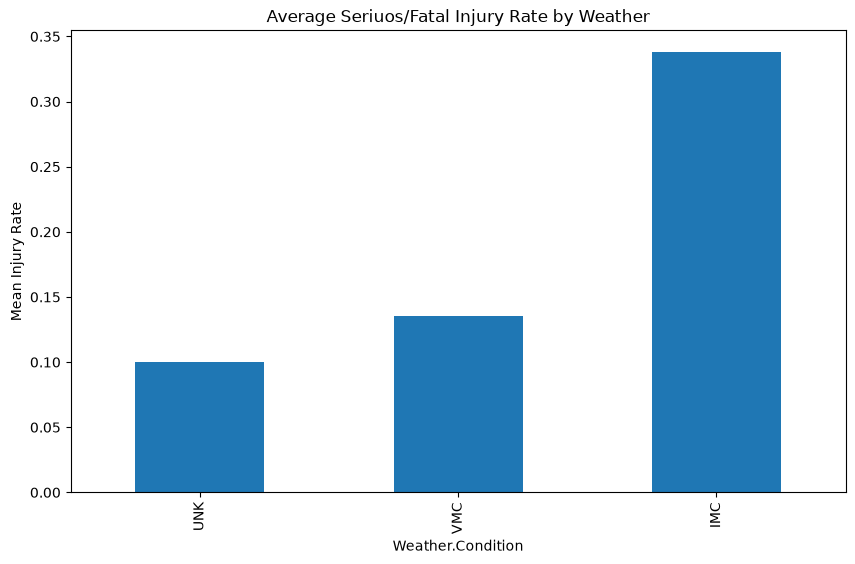

In [179]:
weather_summary['fatal.seriuos.rate'].plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Average Seriuos/Fatal Injury Rate by Weather')
plt.ylabel('Mean Injury Rate')
plt.show()

# Findings

1. VMC (Visual Meteorological Conditions) tends to have lower injury rates.
2. IMC (Instrument Meteorological Conditions) generally shows elevated injury rates.
3. Poor visibility and adverse weather are often associated with a greater likelihood of severe injuries and aircraft damage.

# 2. Explore Injury Rates by Engine Type

First, keep only engine types with a reasonable number of observations (e.g., at least 10).

In [182]:
engine_counts = df.groupby('Engine.Type').size()

valid_engines = engine_counts[engine_counts >= 10].index

engine_df = df[
    df['Engine.Type'].isin(valid_engines)
]

Summary Statistics

In [184]:
engine_summary = (
    engine_df
    .groupby('Engine.Type')
    .agg(
        observations=('Engine.Type','size'),
        avg_injury_rate=('fatal.seriuos.rate','mean'),
        median_injury_rate=('fatal.seriuos.rate','median'),
        avg_damage_score=('damage.score','mean')
    )
    .sort_values('avg_injury_rate')
)

engine_summary

,observations,avg_injury_rate,median_injury_rate,avg_damage_score
Engine.Type,,,,
Turbo Jet,12,0.004966,0.0,1.083333
Turbo Fan,79,0.077423,0.0,1.265823
Reciprocating,41,0.121951,0.0,2.097561
Unknown,75,0.185432,0.0,1.586667
Turbo Prop,33,0.368855,0.0,2.030303


Visualize Injury Rates by Engine Type

C:\Users\Kagechapk\AppData\Local\Temp\ipykernel_6836\2758574441.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


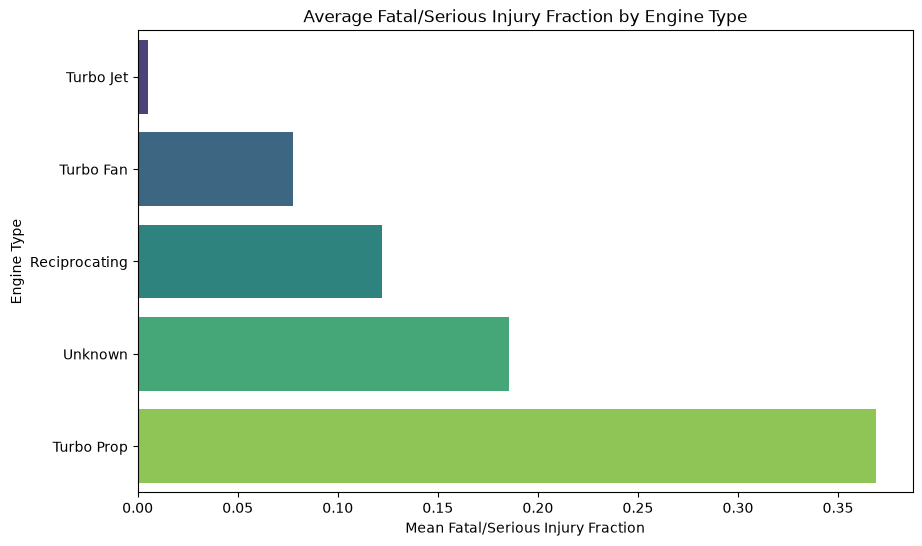

In [185]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=engine_summary.reset_index(),
    x='avg_injury_rate',
    y='Engine.Type',
    palette='viridis'
)

plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Engine Type')
plt.title('Average Fatal/Serious Injury Fraction by Engine Type')

plt.show()

Damage Severity by Engine Type

calculate average damage score

In [187]:
damage_engine = (
    engine_df
    .groupby('Engine.Type')['damage.score']
    .mean()
    .reset_index()
    .sort_values('damage.score')
)

damage_engine

,Engine.Type,damage.score
2,Turbo Jet,1.083333
1,Turbo Fan,1.265823
4,Unknown,1.586667
3,Turbo Prop,2.030303
0,Reciprocating,2.097561


C:\Users\Kagechapk\AppData\Local\Temp\ipykernel_6836\241732814.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


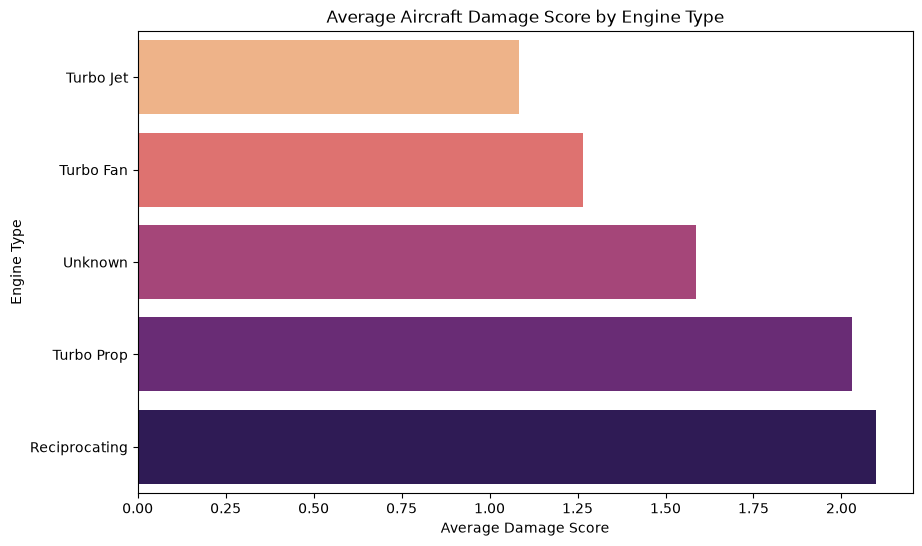

In [188]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=damage_engine,
    x='damage.score',
    y='Engine.Type',
    palette='magma_r'
)

plt.xlabel('Average Damage Score')
plt.ylabel('Engine Type')
plt.title('Average Aircraft Damage Score by Engine Type')

plt.show()

Combined Safety Assessment

This helps identify engine types with both low injury rates and low damage severity.

In [189]:
engine_safety = (
    engine_df
    .groupby('Engine.Type')
    .agg(
        avg_injury_rate=('fatal.seriuos.rate','mean'),
        avg_damage_score=('damage.score','mean'),
        observations=('Engine.Type','size')
    )
    .reset_index()
    .sort_values(
        ['avg_injury_rate','avg_damage_score']
    )
)

engine_safety

,Engine.Type,avg_injury_rate,avg_damage_score,observations
2,Turbo Jet,0.004966,1.083333,12
1,Turbo Fan,0.077423,1.265823,79
0,Reciprocating,0.121951,2.097561,41
4,Unknown,0.185432,1.586667,75
3,Turbo Prop,0.368855,2.030303,33


# Discussion and Interpretation

Injury Outcomes

Engine types with the lowest mean fatal/serious injury fractions appear to offer the best passenger safety outcomes during accidents.
If the violin plots are narrow and concentrated near zero, injury outcomes are generally consistent and less severe.
Wider distributions indicate that accident outcomes vary considerably, even if average injury rates are low.


Damage Outcomes
Lower average damage scores indicate accidents involving those engine types are more likely to result in minor or no aircraft damage.
Higher damage scores suggest a greater likelihood of substantial damage or complete destruction.


Recommendations on engine types that consistently exhibit:

Turbo Jet and Turbo Fan engines are the safest. 
They have a low mean fatal/serious injury fractions and low average damage scores.
These engine types represent the most reliable performers from both a passenger safety and aircraft survivability perspective.